In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## roc-curve

**Figure 2: ROC curves of AI-text detectors on Reddit texts that start with gpt-3.5-turbo output and are finished by a human.** DNA-GPT (Ours) detects on a sliding window of two halves, with (W/ P) or without (W/o P) the golden prompt, while OpenAI's classifier and GPTZero score the whole text; AUC is computed from the plotted curves, and the dashed diagonal marks chance. Both DNA-GPT variants clearly beat the baselines, with AUC 0.987 and 0.905 against 0.647 for GPTZero and 0.565 for OpenAI.

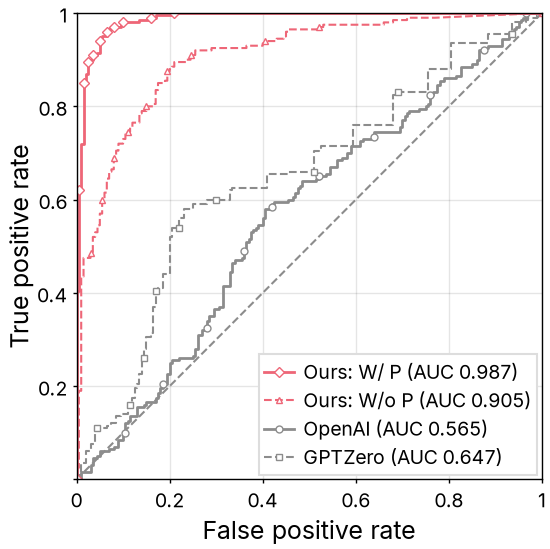

In [2]:
with open("../data/roc-curve.json") as f:
    methods = {m["name"]: m for m in json.load(f)["methods"]}

fig, ax = plt.subplots(figsize=(2.75, 2.75))
ax.axline((0, 0), (1, 1), linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"], zorder=1)
series = [
    ("OpenAI", colors["neutral"], "-", 1.0, "o"),
    ("GPTZero", colors["neutral"], "--", paper.dashed_width, "s"),
    ("Ours: W/o P", colors["ours"], "--", paper.dashed_width, "^"),
    ("Ours: W/ P", colors["ours"], "-", 1.0, "D"),
]
handles = {}
for name, color, linestyle, linewidth, marker in series:
    fpr, tpr = methods[name]["fpr"], methods[name]["tpr"]
    auc = np.trapezoid(tpr, fpr)
    (handles[name],) = ax.plot(fpr, tpr, linestyle=linestyle, linewidth=linewidth, marker=marker,
                               markevery=max(1, len(fpr) // 10), color=color, label=f"{name} (AUC {auc:.3f})")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ticks = [0, 0.2, 0.4, 0.6, 0.8, 1]
ax.set_xticks(ticks, labels=[f"{t:g}" for t in ticks])
ax.set_yticks(ticks, labels=["", *[f"{t:g}" for t in ticks[1:]]])
order = ["Ours: W/ P", "Ours: W/o P", "OpenAI", "GPTZero"]
ax.legend([handles[n] for n in order], [handles[n].get_label() for n in order], loc="lower right")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/roc-curve.pdf")
fig.savefig("../outputs/roc-curve.png")
plt.show()